# Tutorial: closed loop with mis-registered SHs (shifts and rotations)

This notebook shows, step by step, how to run a tomographic loop (LTAO, 4 LGS) with tomoAO when each Shack-Hartmann
has its own shift and rotation with respect to the pupil.

**What tomoAO now does on its own**

1. `AOSystem` reads the mis-registration of each SH from the OOPAO `FieldTransformer` (`wfs.em_field_transform`):
   - it stores it in `wfs_shift_x`, `wfs_shift_y` [px] and `wfs_rotation_angle` [deg];
   - it converts it into an offset [m] and a rotation [rad] of each LGS (`src.offset_x`, `src.offset_y`,
     `src.rotation`);
   - it stores the pupil seen by each SH in `wfs_pupils`.
2. The covariance matrices (Cxx, Cox) use these offsets and rotations to know which points of each layer each SH
   measures.
3. Optionally (`ampl_mask=...`), `tomoReconstructor` builds one Γ block per SH, weighted by the illumination of the
   pupil seen by that SH.

The loop itself does not change: it is the usual POLC.

**In older scripts:**
- **Do not set** the LGS `src.offset_x` / `offset_y` by hand. `AOSystem` sets them from the `FieldTransformer`.
- **Always pass** `wfs=wfs` to `AOSystem`. Without the `wfs`, the SHs are assumed to be aligned.

## 1. Imports

In [1]:
import io, contextlib, warnings, time, math
import numpy as np
# import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
with contextlib.redirect_stdout(io.StringIO()):   # hide the OOPAO banner
    import tomoAO
    from tomoAO.Reconstruction.reconClassType import tomoReconstructor
    from OOPAO.Source import Source
    from OOPAO.Asterism import Asterism
    from OOPAO.Telescope import Telescope
    from OOPAO.Atmosphere import Atmosphere
    from OOPAO.ShackHartmann import ShackHartmann
    from OOPAO.FieldTransformer import FieldTransformer
    from OOPAO.DeformableMirror import DeformableMirror
np.math = math   # aotools uses np.math, which recent numpy versions no longer have

quiet = lambda: contextlib.redirect_stdout(io.StringIO())   # silence the OOPAO prints
print("tomoAO:", tomoAO.__file__)

tomoAO: c:\Users\rsalgueiro\Desktop\Pycharm_projects\Tomo_PhD\.venv\Lib\site-packages\tomoAO\__init__.py


## 2. Parameters

The mis-registration of each SH follows the convention of the OOPAO `FieldTransformer`:
- shift in **pupil pixels**, in x and y;
- rotation in **degrees**.

Here each SH has a shift of ±d/4 (25 % of a subaperture) and a different rotation.

In [2]:
# --- telescope and SH -------------------------------------------------------------------------
D = 8.0                  # [m]
n_sub = 20               # subapertures across
n_px = 8                 # pupil pixels per subaperture
d = n_px                 # subaperture size [px]

sh_type = "geometric"    # "geometric" or "diffractive"
sh_kwargs = {
    "geometric":   dict(is_geometric=True),
    # diffractive: 8 λ/d field of view and no centroid threshold (with a threshold the CoG is very non-linear)
    "diffractive": dict(is_geometric=False, n_pixel_per_subaperture=2 * n_px, threshold_cog=0.0),
}

# --- mis-registration of each SH (FieldTransformer convention) --------------------------------
shift_x        = [d/4, -d/4,  d/4, -d/4]   # [px]
shift_y        = [d/4, -d/4, -d/4,  d/4]   # [px]
rotation_angle = [-6,   -2,    2,    6]    # [deg]

# --- LGS and atmosphere (r0 at 500 nm) --------------------------------------------------------
lgs_zenith, lgs_azimuth, lgs_altitude = 10.0, [0, 90, 180, 270], 90e3
r0, L0 = 0.15, 25
fractional_r0  = [0.5, 0.3, 0.2]
altitude       = [0, 4000, 10000]
wind_speed     = [10, 15, 20]
wind_direction = [0, 90, 180]

# --- reconstructor and loop -------------------------------------------------------------------
os_ = 2                  # oversampling of the reconstruction grid
alpha = 10               # noise weight
ampl_mask = 'hybrid'     # None (standard stencil) or 'hybrid' / 'area' / 'point'
n_loop = 1000            # iterations (1 ms each)
n_skip = 100             # iterations left out of the average (convergence)
gain = 0.5
seed = 42

## 3. Telescope, LGS, atmosphere and DM

Nothing new here.

In [3]:
with quiet():
    tel = Telescope(diameter=D, resolution=n_sub * n_px, centralObstruction=0.2, samplingTime=1e-3,
                    fov=2 * lgs_zenith + 10)
    lgsAst = Asterism([Source(optBand='Na', magnitude=0, coordinates=[lgs_zenith, az], altitude=lgs_altitude)
                       for az in lgs_azimuth])
    lgsAst**tel

    atm = Atmosphere(telescope=tel, src=lgsAst, r0=r0, L0=L0, fractionalR0=fractional_r0,
                     altitude=altitude, windSpeed=wind_speed, windDirection=wind_direction)
    atm.initializeAtmosphere(telescope=tel)

    dm = DeformableMirror(telescope=tel, nSubap=n_sub, mechCoupling=0.35)
    act_mask = np.zeros(dm.nAct ** 2, dtype=bool)
    act_mask[dm.validAct] = True
    dm.unfiltered_act_mask = act_mask.reshape(dm.nAct, dm.nAct)

    mmse_star = Source(optBand='Na', magnitude=0, coordinates=[0, 0])   # direction to optimise (on axis)
    sci = Source(optBand='H', magnitude=0)                              # on-axis science, H band
    sci**tel

## 4. `FieldTransformer` and SH

The `FieldTransformer` shifts and rotates the field reaching each SH: SH `k` sees the pupil with `shift_x[k]`,
`shift_y[k]` and `rotation_angle[k]`. The SH gets it through `em_field_transform`, which is where `AOSystem` reads the
mis-registration from.

In [4]:
with quiet():
    ft = FieldTransformer(src=lgsAst, shift_x=shift_x, shift_y=shift_y, rotation_angle=rotation_angle)
    lgsAst**tel
    wfs = ShackHartmann(telescope=tel, nSubap=n_sub, lightRatio=0.5, shannon_sampling=True,
                        em_field_transform=ft, **sh_kwargs[sh_type])

# valid subapertures of each SH (different, because each SH sees the pupil at a different place)
valid = np.array([wfs.sh_data[f'src_{k}'].valid_subapertures for k in range(len(lgsAst.src))])
print("valid subapertures per SH:", valid.sum(axis=(1, 2)), "| union:", np.logical_or.reduce(valid).sum())

valid subapertures per SH: [304 303 303 303] | union: 320


## 5. `AOSystem`

`AOSystem` takes the `wfs` and does the conversion itself. The valid subapertures of the SHs are combined into a
common mask (here their union).

In [5]:
param = dict(os=os_, nSubaperture=n_sub, mechanicalCoupling=dm.mechCoupling,
             dm_resolution=os_ * n_sub + 1, resolution=tel.resolution)
with quiet():
    aoSys = tomoAO.Simulation.AOSystem(param, tel=tel, atm=atm, dm=dm, lgsAst=lgsAst, mmse_star=mmse_star,
                                       wfs=wfs,                              # <- shifts/rotations come from here
                                       filtered_subap_mask=valid, filtered_subap_mask_operation="union",
                                       os=os_)

# pd.DataFrame({
#     "shift x [px]": aoSys.wfs_shift_x,
#     "shift y [px]": aoSys.wfs_shift_y,
#     "rotation [°]": aoSys.wfs_rotation_angle,
#     "LGS offset_x [cm]": [100 * s.offset_x for s in aoSys.lgsAst],
#     "LGS offset_y [cm]": [100 * s.offset_y for s in aoSys.lgsAst],
#     "LGS rotation [rad]": [s.rotation for s in aoSys.lgsAst],
# }, index=[f"SH{k}" for k in range(len(aoSys.lgsAst))]).round(3)

The LGS offset has the opposite sign of the shift: if the SH sees the pupil shifted by +s, node q of the SH looks at
point q − s of the pupil. There is also a half-pixel term, due to the rotation centre of the `FieldTransformer`.

`aoSys.wfs_pupils` holds the pupil seen by each SH, from which the `ampl_mask` is computed.
- For a geometric SH it is the binary OOPAO `pupil_mask`, the same one it uses to compute the slopes.
- For a diffractive SH it is the transformed pupil with fractional edge pixels (`tools.transformPupil`).

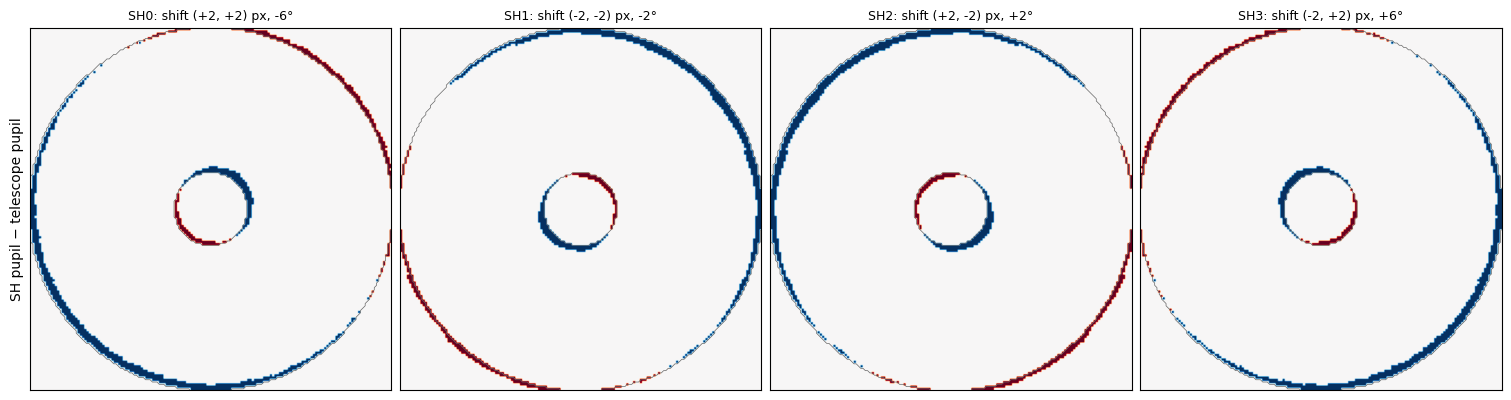

In [6]:
ext = [-D / 2, D / 2, -D / 2, D / 2]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), constrained_layout=True)
for k, ax in enumerate(axes):
    diff = aoSys.wfs_pupils[k] - np.asarray(tel.pupil, float)
    ax.imshow(diff, extent=ext, origin='lower', cmap='RdBu_r', vmin=-1, vmax=1)
    ax.contour(np.asarray(tel.pupil, float), levels=[0.5], extent=ext, colors='0.4', linewidths=0.5)
    ax.set_title(f"SH{k}: shift ({shift_x[k]:+.0f}, {shift_y[k]:+.0f}) px, {rotation_angle[k]:+d}°", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel("SH pupil − telescope pupil")
plt.show()

## 6. Reconstructor

Built as before; the only new argument is `ampl_mask`:
- `None`: Γ with the standard stencil, the same for the 4 SHs. Shifts and rotations enter only through the
  covariances.
- `'hybrid'` (or `'area'` / `'point'`): one Γ block per SH, weighted by the illumination of the nodes in that SH's
  pupil. A list with one precomputed mask per SH is also accepted.

**Careful:** `tomoReconstructor` changes `atm.r0` (it scales it to the LGS wavelength), so the value is restored
afterwards.

In [7]:
def build_reconstructor(ampl_mask):
    with quiet():
        rec = tomoReconstructor(ao_sys=aoSys, alpha=alpha, os=os_, indexation="xxyy", remove_tt_focus=False,
                                filter_subapertures=True, ampl_mask=ampl_mask)
    atm.r0 = r0
    return rec


t0 = time.time()
rec = build_reconstructor(ampl_mask)
R = rec.reconstructor
print(f"R: {R.shape[0]} actuators x {R.shape[1]} slopes  ({time.time() - t0:.0f} s)")

Updating the Atmosphere covariance matrices...
R: 348 actuators x 2426 slopes  (15 s)


## 7. Calibration: slope units and interaction matrix

- `set_slopes_units` fits the scale between the OOPAO slopes and the reconstructor units. R is divided by that factor
  and the SH gets `slopes_units = 1`.
- The interaction matrix M (DM → slopes, through the `FieldTransformer`) is used by the POLC to rebuild the
  open-loop slopes.

In [8]:
def calibrate(R):
    with quiet():
        wfs.set_slopes_units(tomographic_reconstructor=R, src=lgsAst, dm=dm)
    units = wfs.slopes_units
    wfs.slopes_units = 1
    return R / units


def interaction_matrix(stroke=1e-7):
    wfs.slopes_units = 1
    with quiet():
        lgsAst**tel*ft*wfs
        M = np.zeros((np.hstack(wfs.signal).size, dm.nValidAct))
        for i in range(dm.nValidAct):
            dm.coefs = np.eye(dm.nValidAct)[:, i] * stroke
            lgsAst**tel*dm*ft*wfs
            M[:, i] = np.hstack(wfs.signal) / stroke
    dm.coefs = 0
    return M


M = interaction_matrix()
R = calibrate(R)
print("M:", M.shape)

M: (2426, 348)


## 8. Closed loop (POLC)

At each iteration:
1. the atmosphere moves on;
2. the LGSs go through atmosphere → telescope → DM → `FieldTransformer` → SH;
3. the open-loop slopes are $s_{pol} = s_{k-1} - M\,c_k$;
4. the commands are updated with $c_{k+1} = (1-g)\,c_k - g\,R\,s_{pol}$.

The residual is the RMS of the science source OPD inside the pupil. The H-band Strehl is the Maréchal estimate.

In [9]:
def run_loop(R):
    with quiet():
        atm.generateNewPhaseScreen(seed)                 # same turbulence in every run
    dm.coefs = 0
    s_prev = np.zeros(M.shape[0])
    residual = np.zeros(n_loop)
    for i in range(n_loop):
        with quiet():
            atm.update()
            lgsAst**atm*tel*dm*ft*wfs                     # measurement (each SH with its own mis-registration)
            s = np.hstack(wfs.signal)
            s_pol = s_prev - M @ dm.coefs                 # open-loop slopes
            sci**atm*tel*dm                               # on-axis evaluation
        residual[i] = np.std(sci.OPD[tel.pupil == 1]) * 1e9
        dm.coefs = (1 - gain) * dm.coefs - gain * (R @ s_pol)
        s_prev = s
    dm.coefs = 0
    return residual


strehl = lambda res_nm: 100 * np.exp(-(2 * np.pi * res_nm * 1e-9 / sci.wavelength) ** 2)

t0 = time.time()
residual = run_loop(R)
mean = residual[n_skip:].mean()
print(f"mean residual = {mean:.1f} nm RMS, H-band Strehl (Maréchal) = {strehl(mean):.1f} %  ({time.time() - t0:.0f} s)")

mean residual = 108.8 nm RMS, H-band Strehl (Maréchal) = 84.3 %  (60 s)


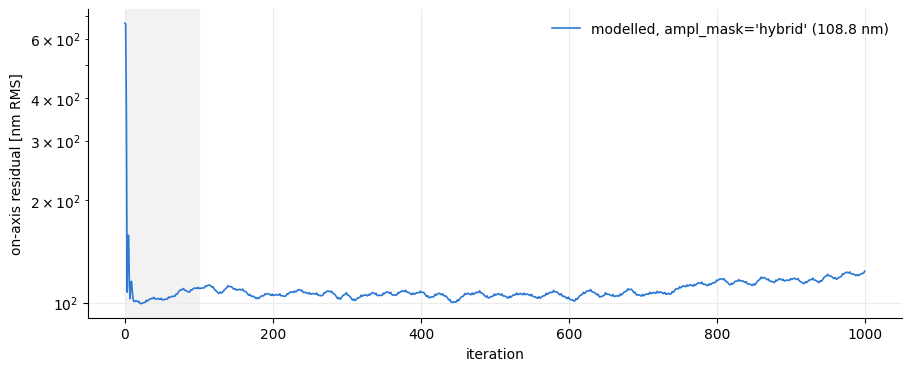

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
ax.plot(residual, color='#2a78d6', lw=1.2, label=f"modelled, ampl_mask={ampl_mask!r} ({mean:.1f} nm)")
ax.axvspan(0, n_skip, color='0.95', zorder=0)
ax.set_yscale('log'); ax.set_xlabel("iteration"); ax.set_ylabel("on-axis residual [nm RMS]")
ax.legend(frameon=False); ax.grid(color='0.92'); ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 9. Check: what if the reconstructor ignores the mis-registration?

To see that the mis-registration is really being modelled, the loop is repeated with a reconstructor that assumes
the SHs are aligned: LGS offsets and rotations set to zero and `ampl_mask=None`. The values are restored at the end.
The turbulence is exactly the same.

Updating the Atmosphere covariance matrices...


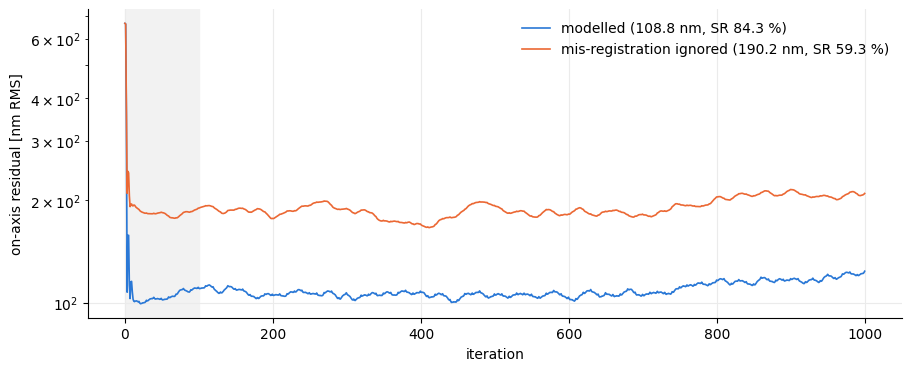

In [11]:
saved = [(s.offset_x, s.offset_y, s.rotation) for s in aoSys.lgsAst]
for s in aoSys.lgsAst:
    s.offset_x = s.offset_y = s.rotation = 0.0
try:
    R_ignore = calibrate(build_reconstructor(None).reconstructor)
finally:
    for s, (ox, oy, th) in zip(aoSys.lgsAst, saved):
        s.offset_x, s.offset_y, s.rotation = ox, oy, th

residual_ignore = run_loop(R_ignore)
mean_ignore = residual_ignore[n_skip:].mean()

fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
ax.plot(residual, color='#2a78d6', lw=1.2, label=f"modelled ({mean:.1f} nm, SR {strehl(mean):.1f} %)")
ax.plot(residual_ignore, color='#eb6834', lw=1.2,
        label=f"mis-registration ignored ({mean_ignore:.1f} nm, SR {strehl(mean_ignore):.1f} %)")
ax.axvspan(0, n_skip, color='0.95', zorder=0)
ax.set_yscale('log'); ax.set_xlabel("iteration"); ax.set_ylabel("on-axis residual [nm RMS]")
ax.legend(frameon=False); ax.grid(color='0.92'); ax.spines[['top', 'right']].set_visible(False)
plt.show()